Khảo sát dữ liệu gốc

1. TỔNG QUAN
Kích thước: (125, 61)
Kiểu dữ liệu:
 int64      27
float64    20
object     14
Dòng trùng lặp: 0
Tổng ô thiếu: 149 (2.0%)

2. MISSING VALUES (toàn bộ cột)
                            so_thieu  ty_le_%
type_sports                       26     20.8
calories_day                      19     15.2
comfort_food_reasons_coded        19     15.2
cuisine                           17     13.6
exercise                          13     10.4
employment                         9      7.2
mother_education                   3      2.4
father_profession                  3      2.4
cook                               3      2.4
eating_changes                     3      2.4
meals_dinner_friend                3      2.4
GPA                                2      1.6
fav_food                           2      1.6
sports                             2      1.6
mother_profession                  2      1.6
fav_cuisine                        2      1.6
drink                              2      1.6
comf

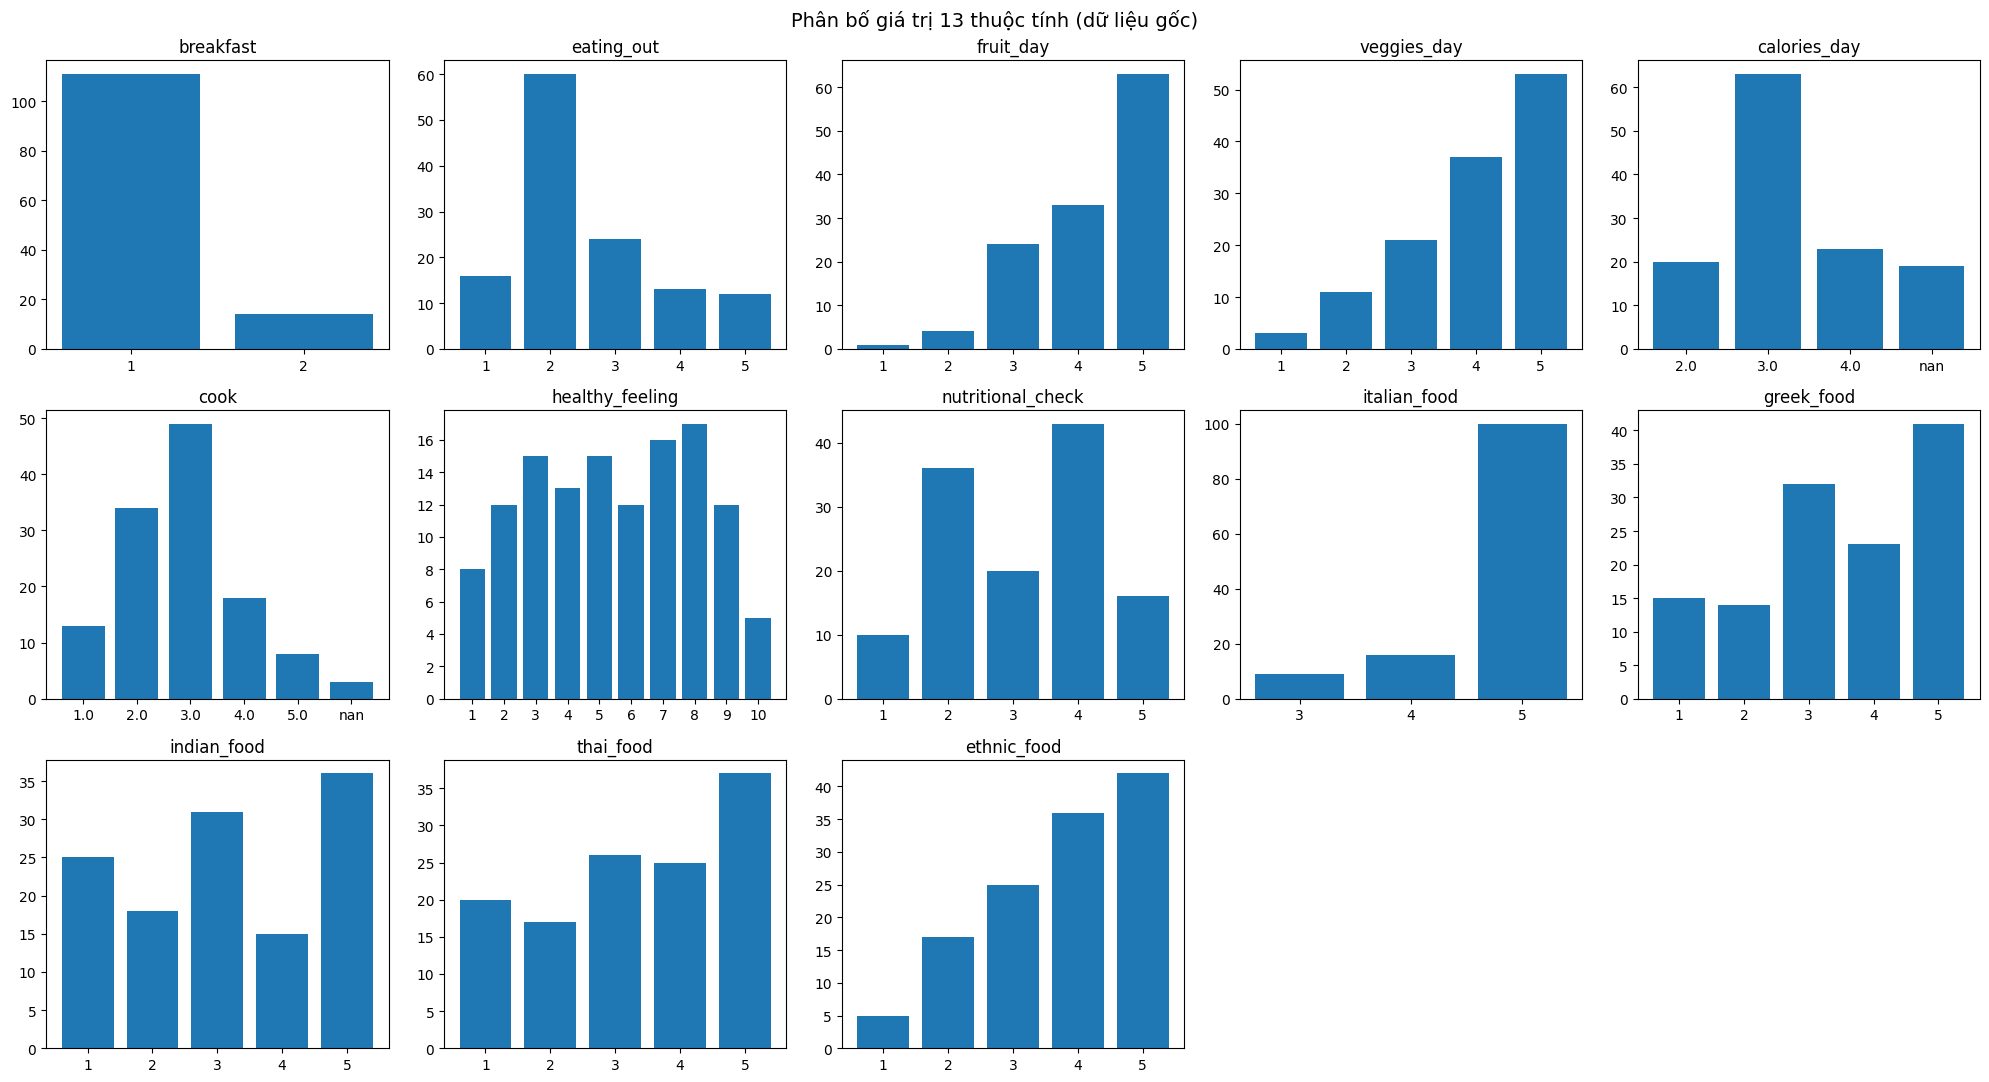

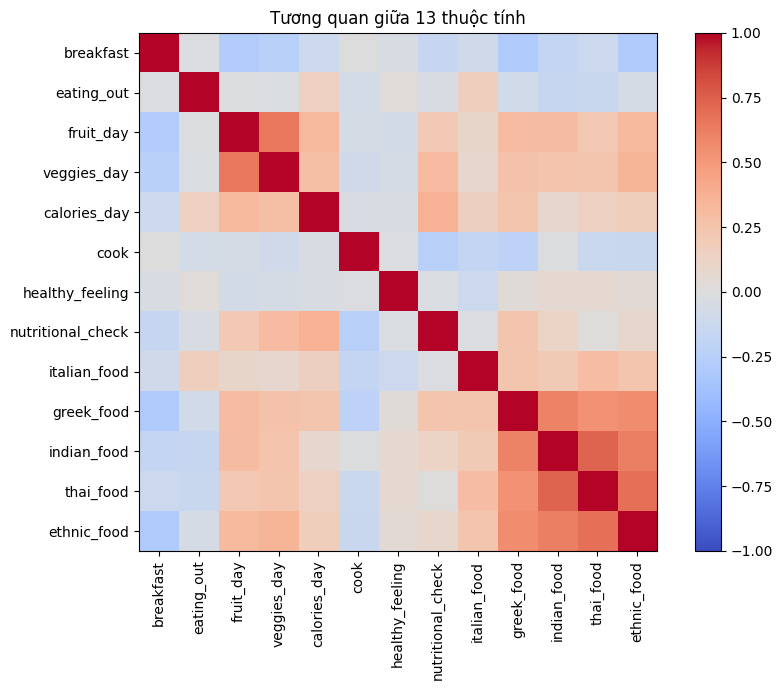

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/KhoaDuong69/Data_Mining_Project/main/Data_Mining_Project/THKTDL/Data/food_coded.csv"
df_raw = pd.read_csv(url)

# ===== 1. TỔNG QUAN =====
print("="*60); print("1. TỔNG QUAN"); print("="*60)
print("Kích thước:", df_raw.shape)
print("Kiểu dữ liệu:\n", df_raw.dtypes.value_counts().to_string())
print("Dòng trùng lặp:", df_raw.duplicated().sum())
print("Tổng ô thiếu:", int(df_raw.isnull().sum().sum()),
      f"({df_raw.isnull().sum().sum()/df_raw.size:.1%})")

# ===== 2. MISSING VALUES TOÀN BỘ 61 CỘT =====
print("\n"+"="*60); print("2. MISSING VALUES (toàn bộ cột)"); print("="*60)
miss_all = pd.DataFrame({
    "so_thieu": df_raw.isnull().sum(),
    "ty_le_%": (df_raw.isnull().mean()*100).round(1)
})
print(miss_all[miss_all.so_thieu > 0].sort_values("so_thieu", ascending=False).to_string())

# ===== 3. THỐNG KÊ MÔ TẢ 13 CỘT ĐƯỢC CHỌN =====
selected_cols = ["breakfast","eating_out","fruit_day","veggies_day","calories_day","cook",
                 "healthy_feeling","nutritional_check","italian_food","greek_food",
                 "indian_food","thai_food","ethnic_food"]
sub = df_raw[selected_cols].apply(pd.to_numeric, errors="coerce")

print("\n"+"="*60); print("3. THỐNG KÊ MÔ TẢ 13 CỘT"); print("="*60)
print(sub.describe().T.round(2).to_string())

# ===== 4. TÓM TẮT THANG ĐO =====
summary = pd.DataFrame({
    "kieu_goc": df_raw[selected_cols].dtypes.astype(str),
    "so_thieu": sub.isnull().sum(),
    "ty_le_thieu_%": (sub.isnull().mean()*100).round(1),
    "min": sub.min(), "max": sub.max(),
    "so_gia_tri_khac_nhau": sub.nunique(),
    "cac_gia_tri": sub.apply(lambda s: sorted(s.dropna().unique().tolist())),
})
print("\n"+"="*60); print("4. TÓM TẮT THANG ĐO"); print("="*60)
print(summary.to_string())

# ===== 5. PHÂN BỐ GIÁ TRỊ + BIỂU ĐỒ =====
print("\n"+"="*60); print("5. PHÂN BỐ GIÁ TRỊ TỪNG CỘT"); print("="*60)
for c in selected_cols:
    print(f"{c}:", sub[c].value_counts(dropna=False).sort_index().to_dict())

fig, axes = plt.subplots(3, 5, figsize=(20, 11)); axes = axes.ravel()
for i, c in enumerate(selected_cols):
    vc = sub[c].value_counts(dropna=False).sort_index()
    axes[i].bar([str(k) for k in vc.index], vc.values)
    axes[i].set_title(c)
for j in range(len(selected_cols), len(axes)):
    axes[j].axis("off")
plt.suptitle("Phân bố giá trị 13 thuộc tính (dữ liệu gốc)", fontsize=14)
plt.tight_layout(); plt.show()

# ===== 6. MA TRẬN TƯƠNG QUAN =====
corr = sub.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
plt.colorbar(im); plt.title("Tương quan giữa 13 thuộc tính"); plt.tight_layout(); plt.show()

Tiền Xử Lý DL

In [ ]:
import pandas as pd
import numpy as np

# =========================
# 1. Đọc dữ liệu
# =========================
url = "https://raw.githubusercontent.com/KhoaDuong69/Data_Mining_Project/main/Data_Mining_Project/THKTDL/Data/food_coded.csv"

df = pd.read_csv(url)

print("Shape ban đầu:", df.shape)

# =========================
# 2. Chọn các thuộc tính cần thiết
# =========================
selected_cols = [
    "breakfast",
    "eating_out",
    "fruit_day",
    "veggies_day",
    "calories_day",
    "cook",
    "healthy_feeling",
    "nutritional_check",
    "italian_food",
    "greek_food",
    "indian_food",
    "thai_food",
    "ethnic_food"
]

df = df[selected_cols]

# =========================
# 3. Kiểm tra Missing Values
# =========================
print("\nMissing Values:")
print(df.isnull().sum())

# =========================
# 4. Xử lý Missing Values
# Dùng median cho cột số
# =========================
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

for col in df.columns:
    df[col].fillna(df[col].median(), inplace=True)

# =========================
# 5. Kiểm tra dữ liệu trùng lặp
# =========================
print("\nDuplicate Rows:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

# =========================
# 6. Rời rạc hóa dữ liệu
# =========================

def categorize_1_5(x):
    if x <= 2:
        return "Low"
    elif x <= 4:
        return "Medium"
    else:
        return "High"

cols_to_bin = [
    "eating_out",
    "fruit_day",
    "veggies_day",
    "cook",
    "healthy_feeling",
    "nutritional_check"
]

for col in cols_to_bin:
    df[col] = df[col].apply(categorize_1_5)

# =========================
# 7. Rời rạc hóa calories_day
# =========================
df["calories_day"] = pd.cut(
    df["calories_day"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

# =========================
# 8. Chuyển các cột sở thích thực phẩm
# =========================

food_cols = [
    "italian_food",
    "greek_food",
    "indian_food",
    "thai_food",
    "ethnic_food"
]

for col in food_cols:
    df[col] = df[col].apply(categorize_1_5)

# =========================
# 9. Chuyển breakfast
# =========================
df["breakfast"] = df["breakfast"].map({
    1: "Breakfast_No",
    2: "Breakfast_Yes"
})

# =========================
# 10. One-Hot Encoding
# =========================
transaction_df = pd.get_dummies(df)

transaction_df = transaction_df.astype(int)

print("\nShape sau encoding:")
print(transaction_df.shape)

print(transaction_df.head())

# =========================
# 11. Lưu dữ liệu
# =========================
transaction_df.to_csv(
    "food_association_ready.csv",
    index=False
)

print("\nĐã lưu file: food_association_ready.csv")


Shape ban đầu: (125, 61)

Missing Values:
breakfast             0
eating_out            0
fruit_day             0
veggies_day           0
calories_day         19
cook                  3
healthy_feeling       0
nutritional_check     0
italian_food          0
greek_food            0
indian_food           0
thai_food             0
ethnic_food           0
dtype: int64

Duplicate Rows: 0

Shape sau encoding:
(125, 37)
   breakfast_Breakfast_No  breakfast_Breakfast_Yes  eating_out_High  \
0                       1                        0                0   
1                       1                        0                0   
2                       1                        0                0   
3                       1                        0                0   
4                       1                        0                0   

   eating_out_Low  eating_out_Medium  fruit_day_High  fruit_day_Low  \
0               0                  1               1              0   
1             

/tmp/ipykernel_2219/4034235066.py:48: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
